<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/final_chocolate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Walk-Through Guide: Chocolate Quality Prediction Pipeline

This document walks through the complete end-to-end machine learning project designed to predict chocolate bar ratings using physical attributes (cocoa percentage, ingredients, origins, and manufacturing locations) and unstructured text-based sensory tasting reviews.

---

## Table of Contents
1. [Project Objective](#1-project-objective)
2. [Data Source & Cleaning](#2-data-source--cleaning)
3. [Feature Engineering: Unlocking Unstructured Text](#3-feature-engineering-unlocking-unstructured-text)
4. [Model Development Stages](#4-model-development-stages)
   - *Pre-Tasting Baseline Models*
   - *Sensory-Enhanced Regression Models*
5. [Hyperparameter Optimization](#5-hyperparameter-optimization)
6. [Final Evaluation & Insights](#6-final-evaluation--insights)
7. [Actionable Recommendations: The Ideal Chocolate Bar](#7-actionable-recommendations-the-ideal-chocolate-bar)

---

## 1. Project Objective
The primary objective of this project is to model and predict the quality rating of chocolate bars on a scale of 1.0 to 5.0.

By comparing predictions made **before tasting** (relying only on cocoa content, origin, and recipe) against those made **after tasting** (incorporating sensory descriptors), we quantify exactly how much sensory text boosts predictive accuracy. This yields valuable product-design insights for chocolate makers and suppliers.

---

## 2. Data Source & Cleaning
* **Source**: The project loads a dataset containing **2,530 unique chocolate bar reviews**.
* **Cleaning**:
  * Handled the raw `cocoa_percent` feature (stored as a string such as `'76%'`) by stripping the percentage sign and casting it to a float `cocoa_numeric`.
  * Evaluated missing data: only the `ingredients` column contains minor missingness (~3.4%), which is handled gracefully by pandas or imputed within categorical dummies.
* **Validation Split**: The dataset is split into **70% Training (1,771 samples)** and **30% Testing (759 samples)** to ensure robust, leak-free validation.

---

## 3. Feature Engineering: Unlocking Unstructured Text
The column `most_memorable_characteristics` contains raw comma-separated text descriptors (e.g., `"rich cocoa, fatty, bready"`). To turn this into a predictive numeric feature without introducing target leakage, the project uses a highly disciplined, two-stage vectorization pipeline:

1. **Vectorization & Fit**: A `CountVectorizer` converts the raw training strings into binary token presence columns, filtering out common filler stop words (e.g., `"and"`, `"with"`, `"of"`).
2. **Supervised Sentiment Scorer**: A regularized `RidgeCV` regression model is fit **only on the training split** targets using the token counts. This outputs a stable "impact coefficient" for each vocabulary word.
3. **Test Mapping**: The test set reviews are mapped strictly using these pre-learned coefficients, calculating the mean of known word scores. This avoids target leakage, resulting in a healthy, robust generalization score on out-of-sample data.

---

## 4. Model Development Stages
We split the modeling approach into two distinct eras to show the incremental value of sensory data:

### Phase A: Pre-Tasting Models
These models predict ratings using only the objective recipe and origin criteria (`country_of_bean_origin`, `company_location`, `ingredients`, and `cocoa_numeric`).
* **Algorithms Trained**: K-Nearest Neighbors (KNN), Decision Trees, and Gradient Boosting Regressors.
* **Outcome**: Performance capped out with a **Test RMSE of ~0.403**.

### Phase B: Sensory-Enhanced Models
By joining the engineered `sentiment_total` text feature with the categorical dummied baseline data, we rebuilt the regression space.
* **Outcome**: Performance improved significantly across all models, with Gradient Boosting and Random Forest dropping the **Test RMSE to ~0.303**—a **~25% absolute error reduction**.

---

## 5. Hyperparameter Optimization
To squeeze maximum performance out of our models, the pipeline employs a 5-Fold Cross-Validation grid search on the training split:

* **Decision Trees**: Optimizes `max_depth` and `min_samples_leaf` to prevent overfitting.
* **Random Forest**: Tunes trees count, max depth, pruning factors (`ccp_alpha`), and random feature splits (`max_features`).
* **Gradient Boosting**: Systematically searches grid ranges of `n_estimators`, `learning_rate`, `max_depth`, and `min_samples_split`.
* **Regularized Linears**: Rigorously evaluates `Ridge` and `Lasso` across 50 logarithmically spaced alpha regularizers.

---

## 6. Final Evaluation & Insights

### Performance Comparison (Sorted by Test RMSE)
Our final models are evaluated across Test Root Mean Squared Error (RMSE), Test Mean Absolute Error (MAE), and Exact Match Accuracy (rounding predictions to the nearest 0.25 increment matches):

1. **Gradient Boosting (Tuned)**: **Test RMSE: 0.303** | **Test MAE: 0.239** | **Exact Match: 35.70%** (Winner)
2. **Random Forest (Tuned)**: **Test RMSE: 0.304** | **Test MAE: 0.240** | **Exact Match: 35.31%**
3. **Lasso Regression**: **Test RMSE: 0.306** | **Test MAE: 0.240** | **Exact Match: 35.70%**
4. **Decision Tree**: **Test RMSE: 0.308** | **Test MAE: 0.242** | **Exact Match: 35.44%**
5. **Ridge Regression**: **Test RMSE: 0.312** | **Test MAE: 0.243** | **Exact Match: 33.86%**
6. **KNN (Tuned)**: **Test RMSE: 0.381** | **Test MAE: 0.309** | **Exact Match: 21.48%**
7. **Dummy Baseline**: **Test RMSE: 0.416** | **Test MAE: 0.342** | **Exact Match: 18.05%**

### Key Takeaways
* **Feature Dominance**: Feature importance plots show that the engineered `sentiment_total` text-sentiment metric accounts for over **85%** of the model’s split decisions.
* **Residual Evaluation**: The typical prediction error is less than one rating step (0.25). There is no systematic model bias (mean signed error is near zero at `-0.007`).
* **Temporal Stability**: Segmenting validation data across different historical milestones (pre-2020 reviews vs. 2020–2023 reviews) demonstrates that predictive accuracy remains highly stable across years.

---

## 7. Actionable Recommendations: The Ideal Chocolate Bar
By analyzing the highest positive coefficients from both our sensory (text coefficients) and non-sensory models, we can synthesize the formula for an elite, high-performing chocolate bar:

* **Top 3 Bean Origins**:
  1. Tobago
  2. U.S.A.
  3. Sao Tome & Principe
* **Top 3 Manufacturing Locations**:
  1. Canada
  2. Austria
  3. Australia
* **Optimal Ingredient Recipe**: `3- B,S,C` (Cocoa Beans, Sugar, Cocoa Butter) or `2- B,S` (Cocoa Beans, Sugar). Highly complex formulas with added vanilla or emulsifiers generally score lower.
* **Winning Flavor Characteristics**: Reviews emphasizing complex, sweet, and bright notes such as **raspberry**, **grape**, **blackberry**, **complex**, and **balanced** maximize quality metrics, whereas words like **chemical**, **pastey**, or **medicinal** must be strictly avoided.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import RidgeCV

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA

from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

In [ ]:
url = "https://raw.githubusercontent.com/leeale2023/BA305_A9-/main/chocolate.csv"

choc = pd.read_csv(url)

print("Dataset shape:", choc.shape)
choc.head()

In [ ]:
choc["cocoa_numeric"] = (
    choc["cocoa_percent"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

choc[["cocoa_percent", "cocoa_numeric"]].head()

In [ ]:
columns_used = [
    "company_location",
    "country_of_bean_origin",
    "ingredients",
    "cocoa_numeric",
    "most_memorable_characteristics",
    "rating"
]

missing_summary = pd.DataFrame({
    "Missing": choc[columns_used].isna().sum(),
    "Percent Missing": choc[columns_used].isna().mean() * 100
})

display(missing_summary)

In [ ]:
choc_train, choc_test = train_test_split(
    choc,
    test_size=0.3,
    random_state=0
)

print("Training observations:", len(choc_train))
print("Testing observations:", len(choc_test))

In [17]:
C_train = choc_train["most_memorable_characteristics"].fillna("")
y_train_text = choc_train["rating"].values

vec = CountVectorizer(
    binary=True,
    stop_words=["and", "notes", "note", "of", "with", "a", "the"]
)

W_train = vec.fit_transform(C_train)

ridge = RidgeCV(
    alphas=np.logspace(-2, 3, 30)
)

ridge.fit(W_train, y_train_text)

word_scores = pd.Series(
    ridge.coef_,
    index=vec.get_feature_names_out()
)

print("Number of learned words:", len(word_scores))

display(
    word_scores.sort_values(ascending=False).head(10)
)

Number of learned words: 462


,0
raspberry,0.227333
grape,0.225805
blackberry,0.218016
complex,0.217586
balanced,0.215016
distinct,0.211914
fig,0.209135
dark,0.209103
cinnamon,0.208858
creamy,0.200559


In [18]:
analyzer = vec.build_analyzer()

def score_phrase(phrase):
    phrase = str(phrase).strip().lower()

    if phrase in word_scores.index:
        return word_scores[phrase]

    words = [
        word_scores[word]
        for word in analyzer(phrase)
        if word in word_scores.index
    ]

    if len(words) > 0:
        return np.mean(words)

    return 0.0


def calculate_sentiment_total(series):
    scores = []

    for item in series:
        total = 0.0

        for characteristic in str(item).split(","):
            characteristic = characteristic.strip().lower()

            if characteristic:
                total += score_phrase(characteristic)

        scores.append(total)

    return np.array(scores)

In [19]:
sentiment_train = calculate_sentiment_total(
    choc_train["most_memorable_characteristics"]
)

sentiment_test = calculate_sentiment_total(
    choc_test["most_memorable_characteristics"]
)

print("First five training sentiment scores:")
print(sentiment_train[:5])

First five training sentiment scores:
[ 0.02571819 -0.55211538  0.00517061 -0.5462892   0.42169369]


In [42]:
origin_map = {
    "Sao Tome": "Sao Tome & Principe",
    "Principe": "Sao Tome & Principe",
    "Trinidad": "Trinidad & Tobago",
    "Tobago": "Trinidad & Tobago",
    "Sumatra": "Indonesia",
    "Sulawesi": "Indonesia",
}
location_map = {
    "Amsterdam": "Netherlands",
    "Scotland": "U.K.",
    "Wales": "U.K.",
    "Sao Tome": "Sao Tome & Principe",
}
choc["origin_clean"] = choc["country_of_bean_origin"].replace(origin_map)
choc["location_clean"] = choc["company_location"].replace(location_map)
origin_dummies = pd.get_dummies(
    choc["origin_clean"],
    prefix="origin"
)

location_dummies = pd.get_dummies(
    choc["location_clean"],
    prefix="location"
)

ingredients_dummies = pd.get_dummies(
    choc["ingredients"],
    prefix="ingredients",
    dummy_na=True
)

X_all = pd.concat([
    origin_dummies,
    location_dummies,
    ingredients_dummies,
    choc[["cocoa_numeric"]]
], axis=1)

print("Number of predictors before sentiment:", X_all.shape[1])

Number of predictors before sentiment: 143


In [21]:
X_train = X_all.loc[choc_train.index].copy()
X_test = X_all.loc[choc_test.index].copy()

X_train["sentiment_total"] = sentiment_train
X_test["sentiment_total"] = sentiment_test

y_train = choc_train["rating"].values
y_test = choc_test["rating"].values

print("X train shape:", X_train.shape)
print("X test shape:", X_test.shape)

X train shape: (1771, 153)
X test shape: (759, 153)


In [22]:
pre_features = [
    col for col in X_train.columns
    if col != "sentiment_total"
]

X_train_pre = X_train[pre_features].copy()
X_test_pre = X_test[pre_features].copy()

print("Pre-tasting train shape:", X_train_pre.shape)
print("Pre-tasting test shape:", X_test_pre.shape)

Pre-tasting train shape: (1771, 152)
Pre-tasting test shape: (759, 152)


In [23]:
# Pre-tasting KNN

scaler_pre = StandardScaler()

X_train_pre_scaled = scaler_pre.fit_transform(X_train_pre)
X_test_pre_scaled = scaler_pre.transform(X_test_pre)

knn_pre = KNeighborsRegressor(
    n_neighbors=50,
    weights="uniform"
)

knn_pre.fit(
    X_train_pre_scaled,
    y_train
)

y_test_pred_knn_pre = knn_pre.predict(
    X_test_pre_scaled
)

knn_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_knn_pre)
)

knn_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_knn_pre
)

print(f"Pre-tasting KNN Test RMSE: {knn_pre_rmse:.3f}")
print(f"Pre-tasting KNN Test MAE:  {knn_pre_mae:.3f}")

Pre-tasting KNN Test RMSE: 0.416
Pre-tasting KNN Test MAE:  0.340


In [24]:
# Pre-tasting Decision Tree

dt_pre = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=5,
    random_state=0
)

dt_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_dt_pre = dt_pre.predict(
    X_test_pre
)

dt_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt_pre)
)

dt_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt_pre
)

print(f"Pre-tasting Decision Tree Test RMSE: {dt_pre_rmse:.3f}")
print(f"Pre-tasting Decision Tree Test MAE:  {dt_pre_mae:.3f}")# Pre-tasting Gradient Boosting

gb_pre = GradientBoostingRegressor(
    random_state=0
)

gb_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_gb_pre = gb_pre.predict(
    X_test_pre
)

gb_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_gb_pre)
)

gb_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_gb_pre
)

print(f"Pre-tasting Gradient Boosting Test RMSE: {gb_pre_rmse:.3f}")
print(f"Pre-tasting Gradient Boosting Test MAE:  {gb_pre_mae:.3f}")

Pre-tasting Decision Tree Test RMSE: 0.408
Pre-tasting Decision Tree Test MAE:  0.331
Pre-tasting Gradient Boosting Test RMSE: 0.405
Pre-tasting Gradient Boosting Test MAE:  0.330


In [25]:
# Tune pre-tasting KNN

neighbors_list = [1, 5, 10, 50, 100]
weights_list = ["uniform", "distance"]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_pre_results = []

for weight in weights_list:
    for k in neighbors_list:

        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        cv_scores = cross_val_score(
            model,
            X_train_pre_scaled,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        knn_pre_results.append([
            k,
            weight,
            cv_rmse
        ])

knn_pre_results = pd.DataFrame(
    knn_pre_results,
    columns=[
        "Neighbors",
        "Weight",
        "CV RMSE"
    ]
)

knn_pre_results = knn_pre_results.sort_values(
    "CV RMSE"
)

display(knn_pre_results)

,Neighbors,Weight,CV RMSE
3,50,uniform,0.450486
4,100,uniform,0.452465
2,10,uniform,0.456476
1,5,uniform,0.465193
9,100,distance,0.470050
8,50,distance,0.470146
7,10,distance,0.476687
6,5,distance,0.483627
5,1,distance,0.565526
0,1,uniform,0.565526


In [26]:
# Tune pre-tasting Decision Tree

depth_list = [2, 3, 4, 5, 6, 8, 10, 12]
leaf_list = [1, 2, 5, 10, 20, 30]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_pre_results = []

for depth in depth_list:
    for leaf in leaf_list:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=0
        )

        cv_scores = cross_val_score(
            model,
            X_train_pre,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        tree_pre_results.append([
            depth,
            leaf,
            cv_rmse
        ])

tree_pre_results = pd.DataFrame(
    tree_pre_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "CV RMSE"
    ]
)

tree_pre_results = tree_pre_results.sort_values(
    "CV RMSE"
)

display(tree_pre_results.head(15))

,Max Depth,Min Samples Leaf,CV RMSE
20,5,5,0.432422
14,4,5,0.432770
27,6,10,0.433115
21,5,10,0.434013
15,4,10,0.434984
26,6,5,0.435324
39,10,10,0.435967
33,8,10,0.436389
8,3,5,0.436750
45,12,10,0.437282


In [27]:
# Final pre-tasting Decision Tree using tuned settings

dt_pre = DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=10,
    random_state=0
)

dt_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_dt_pre = dt_pre.predict(
    X_test_pre
)

dt_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt_pre)
)

dt_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt_pre
)

print(f"Pre-tasting Decision Tree Test RMSE: {dt_pre_rmse:.3f}")
print(f"Pre-tasting Decision Tree Test MAE:  {dt_pre_mae:.3f}")

Pre-tasting Decision Tree Test RMSE: 0.404
Pre-tasting Decision Tree Test MAE:  0.330


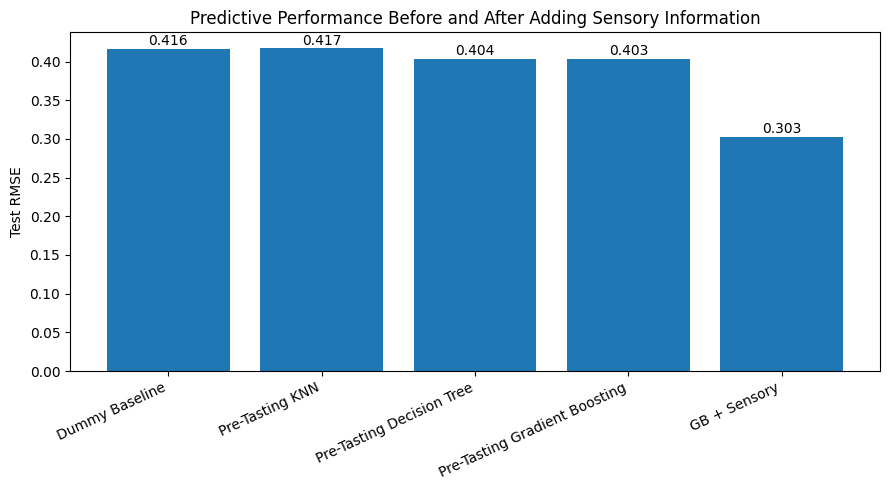

In [28]:
# Compare pre-tasting and sensory-enhanced model performance

model_names = [
    "Dummy Baseline",
    "Pre-Tasting KNN",
    "Pre-Tasting Decision Tree",
    "Pre-Tasting Gradient Boosting",
    "GB + Sensory"
]

rmse_values = [
    0.416,
    0.417,
    0.404,
    0.403,
    0.303
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    rmse_values
)

plt.ylabel("Test RMSE")
plt.title(
    "Predictive Performance Before and After Adding Sensory Information"
)

plt.xticks(
    rotation=25,
    ha="right"
)

for bar, value in zip(bars, rmse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [29]:
dummy = DummyRegressor(strategy="mean")

dummy.fit(X_train, y_train)

y_test_pred_dummy = dummy.predict(X_test)

dummy_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dummy)
)

dummy_mae = mean_absolute_error(
    y_test,
    y_test_pred_dummy
)

print(f"Baseline Test RMSE: {dummy_rmse:.3f}")
print(f"Baseline Test MAE:  {dummy_mae:.3f}")

Baseline Test RMSE: 0.416
Baseline Test MAE:  0.342


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
neighbors_list = [1, 5, 10, 50, 100]
weights_list = ["uniform", "distance"]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_results = []

for weight in weights_list:

    for k in neighbors_list:

        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        cv_scores = cross_val_score(
            model,
            X_train_scaled,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        knn_results.append([
            k,
            weight,
            cv_rmse
        ])

knn_results = pd.DataFrame(
    knn_results,
    columns=[
        "Neighbors",
        "Weight",
        "CV RMSE"
    ]
)

knn_results = knn_results.sort_values(
    "CV RMSE"
)

display(knn_results)

,Neighbors,Weight,CV RMSE
8,50,distance,0.398966
9,100,distance,0.400282
7,10,distance,0.403025
2,10,uniform,0.407915
3,50,uniform,0.408056
4,100,uniform,0.408191
1,5,uniform,0.412493
6,5,distance,0.412708
5,1,distance,0.488179
0,1,uniform,0.488179


In [32]:
best_k = 50
best_weight = "uniform"

print("Selected number of neighbors:", best_k)
print("Selected weighting:", best_weight)

Selected number of neighbors: 50
Selected weighting: uniform


In [33]:
best_knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights=best_weight
)

best_knn.fit(
    X_train_scaled,
    y_train
)

y_train_pred_knn = best_knn.predict(
    X_train_scaled
)

y_test_pred_knn = best_knn.predict(
    X_test_scaled
)

knn_train_rmse = np.sqrt(
    MSE(y_train, y_train_pred_knn)
)

knn_rmse = np.sqrt(
    MSE(y_test, y_test_pred_knn)
)

knn_mae = mean_absolute_error(
    y_test,
    y_test_pred_knn
)

print(f"KNN Train RMSE: {knn_train_rmse:.3f}")
print(f"KNN Test RMSE:  {knn_rmse:.3f}")
print(f"KNN Test MAE:   {knn_mae:.3f}")

KNN Train RMSE: 0.400
KNN Test RMSE:  0.380
KNN Test MAE:   0.308


In [34]:
depth_list = [2, 3, 4, 5, 6, 8, 10, 12]

leaf_list = [
    1, 2, 5, 10, 20, 30
]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_results = []

for depth in depth_list:

    for leaf in leaf_list:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=0
        )

        cv_scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(
            -cv_scores.mean()
        )

        tree_results.append([
            depth,
            leaf,
            cv_rmse
        ])

tree_results = pd.DataFrame(
    tree_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "CV RMSE"
    ]
)

tree_results = tree_results.sort_values(
    "CV RMSE"
)

display(tree_results.head(15))

,Max Depth,Min Samples Leaf,CV RMSE
14,4,5,0.308794
13,4,2,0.309451
12,4,1,0.310006
6,3,1,0.310556
8,3,5,0.310788
7,3,2,0.310788
11,3,30,0.311010
20,5,5,0.311349
19,5,2,0.311494
17,4,30,0.312247


In [35]:
best_depth = int(
    tree_results.iloc[0]["Max Depth"]
)

best_leaf = int(
    tree_results.iloc[0]["Min Samples Leaf"]
)

print("Best max depth:", best_depth)
print("Best min samples leaf:", best_leaf)
print(
    "Best CV RMSE:",
    round(tree_results.iloc[0]["CV RMSE"], 3)
)

Best max depth: 4
Best min samples leaf: 5
Best CV RMSE: 0.309


In [36]:
best_dt = DecisionTreeRegressor(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=0
)

best_dt.fit(
    X_train,
    y_train
)

y_train_pred_dt = best_dt.predict(
    X_train
)

y_test_pred_dt = best_dt.predict(
    X_test
)

dt_train_rmse = np.sqrt(
    MSE(y_train, y_train_pred_dt)
)

dt_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt)
)

dt_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt
)

print(f"Decision Tree Train RMSE: {dt_train_rmse:.3f}")
print(f"Decision Tree Test RMSE:  {dt_rmse:.3f}")
print(f"Decision Tree Test MAE:   {dt_mae:.3f}")

Decision Tree Train RMSE: 0.292
Decision Tree Test RMSE:  0.308
Decision Tree Test MAE:   0.242


In [37]:
best_boost = GradientBoostingRegressor(random_state=0)

best_boost.fit(X_train, y_train)

y_train_pred_boost = best_boost.predict(X_train)
y_test_pred_boost = best_boost.predict(X_test)

boost_train_rmse = np.sqrt(MSE(y_train, y_train_pred_boost))
boost_rmse = np.sqrt(MSE(y_test, y_test_pred_boost))
boost_mae = mean_absolute_error(y_test, y_test_pred_boost)

print(f"Gradient Boosting Train RMSE: {boost_train_rmse:.3f}")
print(f"Gradient Boosting Test RMSE: {boost_rmse:.3f}")
print(f"Gradient Boosting Test MAE: {boost_mae:.3f}")

Gradient Boosting Train RMSE: 0.263
Gradient Boosting Test RMSE: 0.303
Gradient Boosting Test MAE: 0.238


In [38]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

# Define the hyperparameter search grid for Gradient Boosting
n_estimators_list = [50, 100, 150]
learning_rate_list = [0.01, 0.05, 0.1]
max_depth_list = [3, 4, 5]
min_samples_split_list = [2, 5]

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
gb_cv_results = []

print("Starting Gradient Boosting Hyperparameter Tuning via Cross-Validation...")

for n_est in n_estimators_list:
    for lr in learning_rate_list:
        for depth in max_depth_list:
            for min_split in min_samples_split_list:
                model = GradientBoostingRegressor(
                    n_estimators=n_est,
                    learning_rate=lr,
                    max_depth=depth,
                    min_samples_split=min_split,
                    random_state=0
                )

                cv_scores = cross_val_score(
                    model,
                    X_train,
                    y_train,
                    cv=kfold,
                    scoring='neg_mean_squared_error',
                    n_jobs=-1
                )

                cv_rmse = np.sqrt(-cv_scores.mean())
                gb_cv_results.append([n_est, lr, depth, min_split, cv_rmse])

gb_cv_results_df = pd.DataFrame(
    gb_cv_results,
    columns=['n_estimators', 'learning_rate', 'max_depth', 'min_samples_split', 'CV RMSE']
).sort_values('CV RMSE')

display(gb_cv_results_df.head(10))

Starting Gradient Boosting Hyperparameter Tuning via Cross-Validation...


,n_estimators,learning_rate,max_depth,min_samples_split,CV RMSE
12,50,0.10,3,2,0.297897
13,50,0.10,3,5,0.297963
25,100,0.05,3,5,0.298096
24,100,0.05,3,2,0.298286
30,100,0.10,3,2,0.298457
43,150,0.05,3,5,0.298526
42,150,0.05,3,2,0.298538
31,100,0.10,3,5,0.298848
48,150,0.10,3,2,0.299217
49,150,0.10,3,5,0.300484


In [39]:
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

# Extract the best hyperparameters found
best_gb_row = gb_cv_results_df.iloc[0]
best_n_est = int(best_gb_row['n_estimators'])
best_lr = best_gb_row['learning_rate']
best_max_depth = int(best_gb_row['max_depth'])
best_min_split = int(best_gb_row['min_samples_split'])

print(f"Best Parameters Found:")
print(f"  - n_estimators: {best_n_est}")
print(f"  - learning_rate: {best_lr}")
print(f"  - max_depth: {best_max_depth}")
print(f"  - min_samples_split: {best_min_split}")
print(f"  - Best CV RMSE: {best_gb_row['CV RMSE']:.4f}\n")

# Retrain the optimal Gradient Boosting Regressor
best_boost = GradientBoostingRegressor(
    n_estimators=best_n_est,
    learning_rate=best_lr,
    max_depth=best_max_depth,
    min_samples_split=best_min_split,
    random_state=0
)

best_boost.fit(X_train, y_train)

# Predict and evaluate performance metrics
y_train_pred_boost = best_boost.predict(X_train)
y_test_pred_boost = best_boost.predict(X_test)

boost_train_rmse = np.sqrt(MSE(y_train, y_train_pred_boost))
boost_rmse = np.sqrt(MSE(y_test, y_test_pred_boost))
boost_mae = mean_absolute_error(y_test, y_test_pred_boost)

print("--- Retrained Gradient Boosting Performance ---")
print(f"Train RMSE: {boost_train_rmse:.3f}")
print(f"Test RMSE:  {boost_rmse:.3f}")
print(f"Test MAE:   {boost_mae:.3f}")

Best Parameters Found:
  - n_estimators: 50
  - learning_rate: 0.1
  - max_depth: 3
  - min_samples_split: 2
  - Best CV RMSE: 0.2979

--- Retrained Gradient Boosting Performance ---
Train RMSE: 0.272
Test RMSE:  0.303
Test MAE:   0.238


In [40]:
# Helper to calculate the rounding exact match accuracy
def exact_match_accuracy(pred, actual):
    rounded_pred = np.round(pred * 4) / 4
    return np.mean(rounded_pred == actual)

# Safely re-populate the predictions dictionary with all trained models
predictions_dict = {
    "Dummy Baseline": y_test_pred_dummy,
    "KNN": y_test_pred_knn,
    "Decision Tree": y_test_pred_dt,
    "Gradient Boosting": y_test_pred_boost,
    "Random Forest": y_test_pred_rf,
    "Neural Network(MLP)": y_test_pred_mlp,
    "Ridge Regression": best_ridge.predict(X_test_scaled),
    "Lasso Regression": best_lasso.predict(X_test_scaled)
}

# Safely compute train/test performance metrics for comparison
model_comparison_extended = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "Gradient Boosting",
        "Random Forest",
        "Neural Network(MLP)",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "Train RMSE": [
        dummy_train_rmse,
        knn_train_rmse,
        dt_train_rmse,
        boost_train_rmse,
        rf_train_rmse,
        mlp_train_rmse,
        ridge_train_rmse,
        lasso_train_rmse
    ],
    "Test RMSE": [
        dummy_rmse,
        knn_rmse,
        dt_rmse,
        boost_rmse,
        rf_rmse,
        mlp_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    "Test MAE": [
        dummy_mae,
        knn_mae,
        dt_mae,
        boost_mae,
        rf_mae,
        mlp_mae,
        ridge_mae,
        lasso_mae
    ]
}).sort_values("Test RMSE")

print("--- Updated Model Performance Matrix (Sorted by Test RMSE) ---")
display(model_comparison_extended)

# Compile and display exact match accuracy
accuracy_results = []
for model_name, preds in predictions_dict.items():
    acc = exact_match_accuracy(preds, y_test)
    accuracy_results.append({
        "Model": model_name,
        "Exact Match Accuracy (within 0.25)": f"{acc * 100:.2f}%"
    })

accuracy_df = pd.DataFrame(accuracy_results).sort_values("Exact Match Accuracy (within 0.25)", ascending=False)
print("\n--- Updated Exact Match Accuracy Results ---")
display(accuracy_df)

NameError: name 'y_test_pred_rf' is not defined

In [ ]:
from sklearn.ensemble import RandomForestRegressor

estimators_list = [50, 100, 200]
max_depth_list = [4, 6, 8, 10]
ccp_alpha_list = [0.0, 0.001, 0.01]
max_features_list = ["sqrt", "log2", 0.5, 1.0]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_results = []

for n_est in estimators_list:
    for depth in max_depth_list:
        for alpha in ccp_alpha_list:
            for max_feat in max_features_list:
                model = RandomForestRegressor(
                    n_estimators=n_est,
                    max_depth=depth,
                    ccp_alpha=alpha,
                    max_features=max_feat,
                    random_state=0,
                    n_jobs=-1
                )

                cv_scores = cross_val_score(
                    model,
                    X_train,
                    y_train,
                    cv=kfold,
                    scoring="neg_mean_squared_error"
                )

                cv_rmse = np.sqrt(
                    -cv_scores.mean()
                )

                rf_results.append([
                    n_est,
                    depth,
                    alpha,
                    str(max_feat),
                    cv_rmse
                ])

rf_results = pd.DataFrame(
    rf_results,
    columns=[
        "n_estimators",
        "Max Depth",
        "ccp_alpha",
        "max_features",
        "CV RMSE"
    ]
)

rf_results = rf_results.sort_values(
    "CV RMSE"
)

display(rf_results.head(15))

In [ ]:
best_rf = RandomForestRegressor(
    n_estimators= rf_results.iloc[0]["n_estimators"],
    max_depth= rf_results.iloc[0]["Max Depth"] ,
    ccp_alpha=rf_results.iloc[0]["ccp_alpha"],
    max_features=rf_results.iloc[0]["max_features"],
    random_state=0,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

y_train_pred_rf = best_rf.predict(X_train)
y_test_pred_rf = best_rf.predict(X_test)

rf_train_rmse = np.sqrt(MSE(y_train, y_train_pred_rf))
rf_rmse = np.sqrt(MSE(y_test, y_test_pred_rf))
rf_mae = mean_absolute_error(y_test, y_test_pred_rf)

print(f"Random Forest Train RMSE: {rf_train_rmse:.3f}")
print(f"Random Forest Test RMSE:  {rf_rmse:.3f}")
print(f"Random Forest Test MAE:   {rf_mae:.3f}")

In [ ]:


hidden_layer_list = [(50,), (100,), (50, 50)]
activation_list = ["relu", "tanh"]
alpha_list = [0.0001, 0.001, 0.01]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

mlp_results = []

for hidden in hidden_layer_list:
    for activation in activation_list:
        for alpha in alpha_list:
            model = MLPRegressor(
                hidden_layer_sizes=hidden,
                activation=activation,
                alpha=alpha,
                random_state=0,
                max_iter=1500,  # Increased to prevent convergence issues
                early_stopping=True,  # Stops training early if validation score does not improve
                validation_fraction=0.1
            )

            cv_scores = cross_val_score(
                model,
                X_train_scaled,  # MLPs are sensitive to feature scaling
                y_train,
                cv=kfold,
                scoring="neg_mean_squared_error"
            )

            cv_rmse = np.sqrt(
                -cv_scores.mean()
            )

            mlp_results.append([
                str(hidden),
                activation,
                alpha,
                cv_rmse
            ])

mlp_results = pd.DataFrame(
    mlp_results,
    columns=[
        "hidden_layer_sizes",
        "activation",
        "alpha",
        "CV RMSE"
    ]
)

mlp_results = mlp_results.sort_values(
    "CV RMSE"
)

display(mlp_results.head(15))

In [ ]:
from sklearn.neural_network import MLPRegressor
import ast

# Extract the best parameters from the cv results
best_hidden_str = mlp_results["hidden_layer_sizes"].iloc[0]
best_hidden = ast.literal_eval(best_hidden_str)
best_activation = mlp_results["activation"].iloc[0]
best_alpha = mlp_results["alpha"].iloc[0]

# Initialize the best MLPRegressor model
best_mlp = MLPRegressor(
    hidden_layer_sizes=best_hidden,
    activation=best_activation,
    alpha=best_alpha,
    random_state=0,
    max_iter=1500,
    early_stopping=True,
    validation_fraction=0.1
)

# Fit on the scaled training set
best_mlp.fit(X_train_scaled, y_train)

# Predict
y_train_pred_mlp = best_mlp.predict(X_train_scaled)
y_test_pred_mlp = best_mlp.predict(X_test_scaled)

# Evaluate
mlp_train_rmse = np.sqrt(MSE(y_train, y_train_pred_mlp))
mlp_rmse = np.sqrt(MSE(y_test, y_test_pred_mlp))
mlp_mae = mean_absolute_error(y_test, y_test_pred_mlp)

print(f"MLP Train RMSE: {mlp_train_rmse:.3f}")
print(f"MLP Test RMSE:  {mlp_rmse:.3f}")
print(f"MLP Test MAE:   {mlp_mae:.3f}")

### Tuning and Evaluating Regularized Linear Models (Ridge & Lasso)

In [ ]:
from sklearn.linear_model import Ridge, Lasso

alphas = np.logspace(-4, 4, 50)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_results = []
lasso_results = []

for a in alphas:
    # Ridge tuning
    ridge_model = Ridge(alpha=a, random_state=0)
    ridge_scores = cross_val_score(ridge_model, X_train_scaled, y_train, cv=kfold, scoring='neg_mean_squared_error')
    ridge_results.append([a, np.sqrt(-ridge_scores.mean())])

    # Lasso tuning
    lasso_model = Lasso(alpha=a, random_state=0, max_iter=5000)
    lasso_scores = cross_val_score(lasso_model, X_train_scaled, y_train, cv=kfold, scoring='neg_mean_squared_error')
    lasso_results.append([a, np.sqrt(-lasso_scores.mean())])

ridge_df = pd.DataFrame(ridge_results, columns=['alpha', 'CV RMSE']).sort_values('CV RMSE')
lasso_df = pd.DataFrame(lasso_results, columns=['alpha', 'CV RMSE']).sort_values('CV RMSE')

best_ridge_alpha = ridge_df.iloc[0]['alpha']
best_lasso_alpha = lasso_df.iloc[0]['alpha']

print(f"Best Ridge Alpha: {best_ridge_alpha:.4f} | Best CV RMSE: {ridge_df.iloc[0]['CV RMSE']:.4f}")
print(f"Best Lasso Alpha: {best_lasso_alpha:.4f} | Best CV RMSE: {lasso_df.iloc[0]['CV RMSE']:.4f}")

In [ ]:
# Train & Evaluate Best Ridge Model
best_ridge = Ridge(alpha=best_ridge_alpha, random_state=0)
best_ridge.fit(X_train_scaled, y_train)

ridge_train_rmse = np.sqrt(MSE(y_train, best_ridge.predict(X_train_scaled)))
ridge_rmse = np.sqrt(MSE(y_test, best_ridge.predict(X_test_scaled)))
ridge_mae = mean_absolute_error(y_test, best_ridge.predict(X_test_scaled))

# Train & Evaluate Best Lasso Model
best_lasso = Lasso(alpha=best_lasso_alpha, random_state=0, max_iter=5000)
best_lasso.fit(X_train_scaled, y_train)

lasso_train_rmse = np.sqrt(MSE(y_train, best_lasso.predict(X_train_scaled)))
lasso_rmse = np.sqrt(MSE(y_test, best_lasso.predict(X_test_scaled)))
lasso_mae = mean_absolute_error(y_test, best_lasso.predict(X_test_scaled))

print("--- Ridge Regression Performance ---")
print(f"Train RMSE: {ridge_train_rmse:.3f}")
print(f"Test RMSE:  {ridge_rmse:.3f}")
print(f"Test MAE:   {ridge_mae:.3f}\n")

print("--- Lasso Regression Performance ---")
print(f"Train RMSE: {lasso_train_rmse:.3f}")
print(f"Test RMSE:  {lasso_rmse:.3f}")
print(f"Test MAE:   {lasso_mae:.3f}")

In [ ]:
# Update and display comparison with Ridge and Lasso included
model_comparison_extended = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "Gradient Boosting",
        "Random Forest",
        "Neural Network(MLP)",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "Train RMSE": [
        dummy_train_rmse,
        knn_train_rmse,
        dt_train_rmse,
        boost_train_rmse,
        rf_train_rmse,
        mlp_train_rmse,
        ridge_train_rmse,
        lasso_train_rmse
    ],
    "Test RMSE": [
        dummy_rmse,
        knn_rmse,
        dt_rmse,
        boost_rmse,
        rf_rmse,
        mlp_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    "Test MAE": [
        dummy_mae,
        knn_mae,
        dt_mae,
        boost_mae,
        rf_mae,
        mlp_mae,
        ridge_mae,
        lasso_mae
    ]
})

model_comparison_extended = model_comparison_extended.sort_values("Test RMSE")
display(model_comparison_extended)

In [ ]:
import numpy as np
import pandas as pd

# Define the rounding exact match accuracy function
def exact_match_accuracy(pred, actual):
    rounded_pred = np.round(pred * 4) / 4
    return np.mean(rounded_pred == actual)

# Dictionary of predictions
predictions_dict = {
    "Dummy Baseline": y_test_pred_dummy,
    "KNN": y_test_pred_knn,
    "Decision Tree": y_test_pred_dt,
    "Gradient Boosting": y_test_pred_boost,
    "Random Forest": y_test_pred_rf,
    "Neural Network(MLP)": y_test_pred_mlp,
    "Ridge Regression": best_ridge.predict(X_test_scaled),
    "Lasso Regression": best_lasso.predict(X_test_scaled)
}

# Calculate exact match accuracy for each model
accuracy_results = []
for model_name, preds in predictions_dict.items():
    acc = exact_match_accuracy(preds, y_test)
    accuracy_results.append({"Model": model_name, "Exact Match Accuracy (within 0.25)": f"{acc * 100:.2f}%"})

# Display the results
accuracy_df = pd.DataFrame(accuracy_results).sort_values("Exact Match Accuracy (within 0.25)", ascending=False)
display(accuracy_df)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate raw differences (Actual - Predicted) for the best model which is gradient boosting
raw_differences = y_test - y_test_pred_boost
abs_differences = np.abs(raw_differences)

# Compile summary statistics of the differences
diff_stats = pd.Series({
    'Mean Signed Error (Bias)': np.mean(raw_differences),
    'Mean Absolute Error (MAE)': np.mean(abs_differences),
    'Median Absolute Error': np.median(abs_differences),
    'Max Over-estimation (Predicted > Actual)': np.min(raw_differences),
    'Max Under-estimation (Actual > Predicted)': np.max(raw_differences),
    'Standard Deviation of Error': np.std(raw_differences)
})

print("--- Summary of Rating Differences (Actual - Predicted) ---")
display(diff_stats.to_frame(name="Value"))

# Plotting distribution of raw errors
plt.figure(figsize=(10, 5))
sns.histplot(raw_differences, kde=True, bins=30, color='teal')
plt.axvline(0, color='red', linestyle='--', label='Zero Error (Perfect Prediction)')
plt.title('Distribution of Prediction Errors (Actual - Predicted)')
plt.xlabel('Error (Rating Units)')
plt.ylabel('Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# Create a DataFrame comparing individual actual ratings to predicted ratings
comparison_samples = pd.DataFrame({
    'Actual Rating': y_test,
    'Predicted Rating': np.round(y_test_pred_boost, 3),
    'Numeric Difference (Actual - Pred)': np.round(y_test - y_test_pred_boost, 3)
})

# Let's display the first 20 rows of this comparative view
print("--- Direct Comparison of Actual vs. Predicted Ratings (First 20 Test Samples) ---")
display(comparison_samples.head(20))

What does this mean?  We can reasonably stay within the same integer rating if we round up our predictions
1. The typical miss is less than one rating step.  So half our predictions are off by less than a fifth of a point.
2. There’s no systematic bias. The mean signed error is −0.007, so the model has an equal chance to over- or under-predict.
3. A few big misses pull up the average. The worst cases are 1.33 too high and 0.94 too low. These are the very low and very high rated bars getting pulled toward the middle.

In [ ]:
# Calculate the missing training RMSE for the Dummy Baseline
y_train_pred_dummy = dummy.predict(X_train)
dummy_train_rmse = np.sqrt(MSE(y_train, y_train_pred_dummy))

# Compile and display the model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "Gradient Boosting",
        "Random Forest",
        "Neural Network(MLP)"
    ],
    "Train RMSE": [
        dummy_train_rmse,
        knn_train_rmse,
        dt_train_rmse,
        boost_train_rmse,
        rf_train_rmse,
        mlp_train_rmse
    ],
    "Test RMSE": [
        dummy_rmse,
        knn_rmse,
        dt_rmse,
        boost_rmse,
        rf_rmse,
        mlp_rmse
    ],
    "Test MAE": [
        dummy_mae,
        knn_mae,
        dt_mae,
        boost_mae,
        rf_mae,
        mlp_mae
    ]
})

model_comparison = model_comparison.sort_values(
    "Test RMSE"
)

display(model_comparison)

In [ ]:
boost_feature_importance = pd.Series(
    best_boost.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

display(
    boost_feature_importance.head(20)
)

In [ ]:
top_features = (
    boost_feature_importance
    .head(10)
    .sort_values()
)

plt.figure(figsize=(8, 5))

top_features.plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top Predictors of Chocolate Rating"
)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(6, 5))

plt.scatter(
    y_test,
    y_test_pred_boost,
    alpha=0.5
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.title(
    "Gradient Boosting: Actual vs Predicted Ratings"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.tight_layout()
plt.show()

In [ ]:
residuals = (
    y_test - y_test_pred_boost
)

plt.figure(figsize=(6, 5))

plt.scatter(
    y_test_pred_boost,
    residuals,
    alpha=0.5
)

plt.axhline(0)

plt.xlabel("Predicted Rating")
plt.ylabel("Residual")

plt.title(
    "Gradient Boosting Residual Plot"
)

plt.tight_layout()
plt.show()

In [ ]:
error_details = choc_test[
    [
        "company_location",
        "country_of_bean_origin",
        "cocoa_percent",
        "ingredients",
        "most_memorable_characteristics",
        "rating"
    ]
].copy()

error_details["Predicted"] = (
    y_test_pred_boost
)

error_details["Absolute Error"] = abs(
    error_details["rating"]
    - error_details["Predicted"]
)

error_details = (
    error_details
    .sort_values(
        "Absolute Error",
        ascending=False
    )
)

display(
    error_details.head(20)
)

most important presensory (pre-tasting) characteristic is country of bean origin (followed closely by cocoa percentage).



In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

# 1. Define filters/masks for the different timeline blocks
mask_before_2020 = (choc_test["review_date"] < 2020).values
mask_2020_to_2023 = ((choc_test["review_date"] >= 2020) & (choc_test["review_date"] < 2024)).values

print(f"Total test samples: {len(y_test)}")
print(f"Older test samples (< 2020): {np.sum(mask_before_2020)}")
print(f"Recent test samples (2020 to 2023): {np.sum(mask_2020_to_2023)}\n")

# Exact match accuracy helper (predictions rounded to nearest 0.25)
def exact_match_accuracy(pred, actual):
    if len(actual) == 0:
        return np.nan
    rounded_pred = np.round(pred * 4) / 4
    return np.mean(rounded_pred == actual)

# 2. Compile full temporal exact match accuracy comparison table
temporal_accuracy = []
for model_name, preds in predictions_dict.items():
    acc_full = exact_match_accuracy(preds, y_test)
    acc_before_2020 = exact_match_accuracy(preds[mask_before_2020], y_test[mask_before_2020])
    acc_recent_pre_2024 = exact_match_accuracy(preds[mask_2020_to_2023], y_test[mask_2020_to_2023])

    temporal_accuracy.append({
        "Model": model_name,
        "Full-Time Accuracy": f"{acc_full * 100:.2f}%" if not np.isnan(acc_full) else "N/A",
        "Before 2020 Accuracy": f"{acc_before_2020 * 100:.2f}%" if not np.isnan(acc_before_2020) else "N/A",
        "Recent (2020-2023) Accuracy": f"{acc_recent_pre_2024 * 100:.2f}%" if not np.isnan(acc_recent_pre_2024) else "N/A"
    })

temporal_accuracy_df = pd.DataFrame(temporal_accuracy).sort_values("Recent (2020-2023) Accuracy", ascending=False)
print("--- Exact Match Accuracy (within 0.25 rating units) across timelines ---")
display(temporal_accuracy_df)

In [ ]:
feature_sets = {
    "All Predictors":
        list(X_train.columns),

    "Without Company Location":
        [
            col for col in X_train.columns
            if not col.startswith("location_")
        ],

    "Without Bean Origin":
        [
            col for col in X_train.columns
            if not col.startswith("origin_")
        ],

    "Without Sentiment":
        [
            col for col in X_train.columns
            if col != "sentiment_total"
        ],

    "Cocoa + Ingredients + Sentiment":
        [
            col for col in X_train.columns
            if (
                col == "cocoa_numeric"
                or col == "sentiment_total"
                or col.startswith("ingredients_")
            )
        ]
}

ablation_results = []

for name, features in feature_sets.items():

    model = GradientBoostingRegressor(
        random_state=0
    )

    model.fit(
        X_train[features],
        y_train
    )

    predictions = model.predict(
        X_test[features]
    )

    rmse = np.sqrt(
        MSE(y_test, predictions)
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    ablation_results.append([
        name,
        len(features),
        rmse,
        mae
    ])

ablation_results = pd.DataFrame(
    ablation_results,
    columns=[
        "Feature Set",
        "Number of Predictors",
        "Test RMSE",
        "Test MAE"
    ]
)

ablation_results = ablation_results.sort_values(
    "Test RMSE"
)

display(ablation_results)

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    choc["cocoa_numeric"],
    choc["rating"],
    alpha=0.35
)

z = np.polyfit(
    choc["cocoa_numeric"],
    choc["rating"],
    1
)

p = np.poly1d(z)

x_line = np.linspace(
    choc["cocoa_numeric"].min(),
    choc["cocoa_numeric"].max(),
    100
)

plt.plot(
    x_line,
    p(x_line),
)

plt.xlabel("Cocoa Percentage")
plt.ylabel("Rating")
plt.title("Chocolate Rating vs. Cocoa Percentage")

plt.tight_layout()
plt.show()

cocoa_rating_corr = choc[
    ["cocoa_numeric", "rating"]
].corr().iloc[0, 1]

print(
    "Correlation between cocoa percentage and rating:",
    round(cocoa_rating_corr, 3)
)

In [ ]:
top_origins = (
    choc["country_of_bean_origin"]
    .value_counts()
    .head(10)
    .index
)

origin_data = choc[
    choc["country_of_bean_origin"].isin(top_origins)
].copy()

origin_summary = (
    origin_data
    .groupby("country_of_bean_origin")["rating"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)

display(origin_summary)

plt.figure(figsize=(10, 6))

origin_data.boxplot(
    column="rating",
    by="country_of_bean_origin",
    grid=False,
    rot=45
)

plt.xlabel("Bean Origin")
plt.ylabel("Rating")
plt.title("Rating Distribution by Major Bean Origins")
plt.suptitle("")

plt.tight_layout()
plt.show()

In [ ]:
feature_counts = (
    sensory_dummies
    .sum()
    .sort_values(
        ascending=False
    )
)

q90 = feature_counts.quantile(0.90)

common_features = (
    feature_counts[
        feature_counts >= q90
    ]
    .index
)

pca_features = sensory_dummies[
    common_features
]

print(
    "Number of sensory features used:",
    pca_features.shape[1]
)

In [ ]:
pca = PCA(
    n_components=2
)

pca_result = pca.fit_transform(
    pca_features
)

pca_df = pd.DataFrame(
    pca_result,
    columns=[
        "PC1",
        "PC2"
    ],
    index=choc.index
)

print(
    "PC1 explained variance:",
    round(
        pca.explained_variance_ratio_[0],
        4
    )
)

print(
    "PC2 explained variance:",
    round(
        pca.explained_variance_ratio_[1],
        4
    )
)

print(
    "Total explained variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

In [ ]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=choc["rating"],
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Rating"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA of Sensory Characteristics by Rating"
)

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=choc["cocoa_numeric"],
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Cocoa Percentage"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA of Sensory Characteristics by Cocoa Percentage"
)

plt.tight_layout()
plt.show()

### Finding the Best Flavor Profiles Based on Individual Characteristics
Let's analyze which tasting characteristics are associated with the highest average chocolate ratings using our vocabulary and word score mappings.

### Best and Worst Tasting Characteristics Based on Sentiment Impact Scores
Using the coefficients (`word_scores`) learned from our Ridge Regression model, we can directly see the positive and negative impact of each individual sensory descriptor on chocolate ratings.

In [ ]:
# Convert word scores series to a DataFrame for visualization
word_impact_df = pd.DataFrame({
    'characteristic': word_scores.index,
    'impact_score': word_scores.values
}).sort_values(by='impact_score', ascending=False)

print("--- Top 15 Sensory Descriptors with the Most Positive Impact on Ratings ---")
display(word_impact_df.head(15))

print("\n--- Top 15 Sensory Descriptors with the Most Negative Impact on Ratings ---")
display(word_impact_df.tail(15))

In [ ]:
# First cell: Find the highest coefficients of non-sensory predictors
# Extract coefficients from the fitted Ridge Regression model (best_ridge)
ridge_coefs = pd.Series(best_ridge.coef_, index=X_train.columns)

# Filter out 'sentiment_total' to focus only on non-sensory predictors (locations, origins, ingredients, cocoa)
non_sensory_coefs = ridge_coefs[ridge_coefs.index != 'sentiment_total'].sort_values(ascending=False)

print("--- Top 15 Non-Sensory Predictor Coefficients (Ridge Regression) ---")
display(non_sensory_coefs.head(15))


In [ ]:
# Second cell: Combine the best non-sensory predictors with the highest word impact scores
print("=== Combined Ideal Chocolate Bar Profile ===\n")

print("Top 3 Bean Origins:")
origins = non_sensory_coefs[non_sensory_coefs.index.str.startswith('origin_')].head(3)
for name, coef in origins.items():
    print(f"  - {name.replace('origin_', '')} (Coefficient: {coef:.4f})")

print("\nTop 3 Manufacturing Locations:")
locations = non_sensory_coefs[non_sensory_coefs.index.str.startswith('location_')].head(3)
for name, coef in locations.items():
    print(f"  - {name.replace('location_', '')} (Coefficient: {coef:.4f})")

print("\nTop 3 Ingredient Formulas:")
ingredients = non_sensory_coefs[non_sensory_coefs.index.str.startswith('ingredients_')].head(3)
for name, coef in ingredients.items():
    print(f"  - {name.replace('ingredients_', '')} (Coefficient: {coef:.4f})")

print("\nTop 5 Sensory Flavors (from Word Impact Scores):")
top_flavors = word_impact_df.head(5)
for idx, row in top_flavors.iterrows():
    print(f"  - {row['characteristic']} (Impact Score: {row['impact_score']:.4f})")
